Dataset: Chicco, D. & Jurman, G. (2020). Sepsis Survival Minimal Clinical Records [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C53C8N (CC BY 4.0)

Objetivo: verificar se a proporção de sobrevivência difere entre pacientes do sexo masculino e feminino

Variáveis: sex_0male_1female (0 = masculino, 1 = feminino); hospital_outcome_1alive_0dead (1 = vivo, 0 = morto). Idade (age_years) e número de episódios (episode_number)

In [7]:
# pip install ucimlrepo
%pip install -q ucimlrepo

import itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency, norm
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

sexo = "sex_0male_1female"
idade = "age_years"
eps = "episode_number"
estado = "hospital_outcome_1alive_0dead"

dataset = fetch_ucirepo(id=827)
X = dataset.data.features
y = dataset.data.targets
print(dataset.metadata)
print(dataset.variables)

{'uci_id': 827, 'name': 'Sepsis Survival Minimal Clinical Records', 'repository_url': 'https://archive.ics.uci.edu/dataset/827/sepsis+survival+minimal+clinical+records', 'data_url': 'https://archive.ics.uci.edu/static/public/827/data.csv', 'abstract': 'The dataset consists of 110,204 admissions of 84,811 hospitalized subjects between 2011 and 2012 in Norway who were diagnosed with infections, systemic inflammatory response syndrome, sepsis by causative microbes, or septic shock.  The prediction task is to determine whether a patient survived or is deceased at a time of about 9 days after collecting their medical record at the hospital.\n\nThis is an important prediction problem in clinical medicine. Sepsis is a life-threatening condition triggered by an immune overreaction to infection, leading to organ failure or even death. Sepsis is associated with immediate death risk, often killing patients within one hour. This renders many laboratory tests and hospital analyses impractical for t

In [8]:
df = pd.concat([X, y], axis=1)
for c in [sexo, idade, eps, estado]:
    assert c in df.columns, f"Coluna ausente: {c}. Colunas: {list(df.columns)}"
df["sexo"] = df[sexo].map({0: "Masculino", 1: "Feminino"})
df["desfecho"] = df[estado].map({1: "Vivo", 0: "Morto"})
print("Dimensões:", df.shape)
df.head()

print("Total de registros:", len(df))
print("Registros por sexo:")
print(df["sexo"].value_counts())

print("\nDistribuição do número de episódios:")
print(df[eps].value_counts().sort_index())

Dimensões: (110341, 6)
Total de registros: 110341
Registros por sexo:
sexo
Masculino    58063
Feminino     52278
Name: count, dtype: int64

Distribuição do número de episódios:
episode_number
1    84926
2    16710
3     5403
4     2199
5     1103
Name: count, dtype: int64


In [9]:
cols = [sexo, idade, eps, estado]
print("Valores ausentes:", int(df[cols].isna().sum().sum()))
print("Valores de sexo:", sorted(df[sexo].dropna().unique()), "| valores do desfecho:", sorted(df[estado].dropna().unique()))

n_dup = int(df.duplicated(subset=cols).sum())
print(f"Linhas duplicadas: {n_dup} ({n_dup / len(df) * 100:.1f}%)")
# com apenas 3 atributos (tirando estado) e sem identificador para cada paciente
# nao podemos afirmar que registros duplicados são erros, então serão mantidos

print("\nIdade:"); print(df[idade].describe().round(1).to_string())
print("Idades < 0 ou > 110:", int(((df[idade] < 0) | (df[idade] > 110)).sum()))
print("\nEpisódios:"); print(df[eps].describe().round(2).to_string())
print("Distribuição dos episódios:"); print(df[eps].value_counts().sort_index().head(8).to_string())

Valores ausentes: 0
Valores de sexo: [np.int64(0), np.int64(1)] | valores do desfecho: [np.int64(0), np.int64(1)]
Linhas duplicadas: 108829 (98.6%)

Idade:
count    110341.0
mean         62.7
std          24.1
min           0.0
25%          51.0
50%          68.0
75%          81.0
max         100.0
Idades < 0 ou > 110: 0

Episódios:
count    110341.00
mean          1.35
std           0.75
min           1.00
25%           1.00
50%           1.00
75%           1.00
max           5.00
Distribuição dos episódios:
episode_number
1    84926
2    16710
3     5403
4     2199
5     1103


,pacientes,%
desfecho,,
Vivo,102212,92.63
Morto,8129,7.37


Razão entre a maior e a menor classe: 12.6
Desbalanceamento:  Sim, a classe majoritaria domina


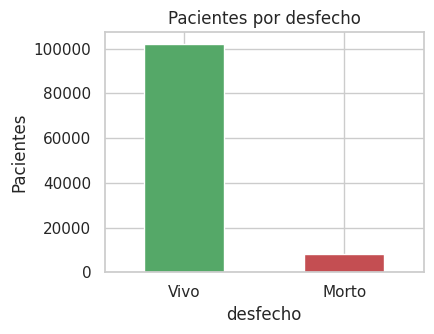

In [10]:
contagem = df["desfecho"].value_counts()
tab = pd.DataFrame({"pacientes": contagem, "%": (contagem / len(df) * 100).round(2)})
display(tab)
razao = contagem.max() / contagem.min()
print(f"Razão entre a maior e a menor classe: {razao:.1f}")
print("Desbalanceamento: ", "Sim, a classe majoritaria domina" if razao >= 3 else "Pequeno ou moderado")

plt.figure(figsize=(4.5,3.5))
contagem.plot(kind="bar", color=['#55A868', '#C44E52']); plt.title("Pacientes por desfecho"), plt.ylabel("Pacientes"), plt.xticks(rotation=0);
plt.tight_layout(); plt.show()

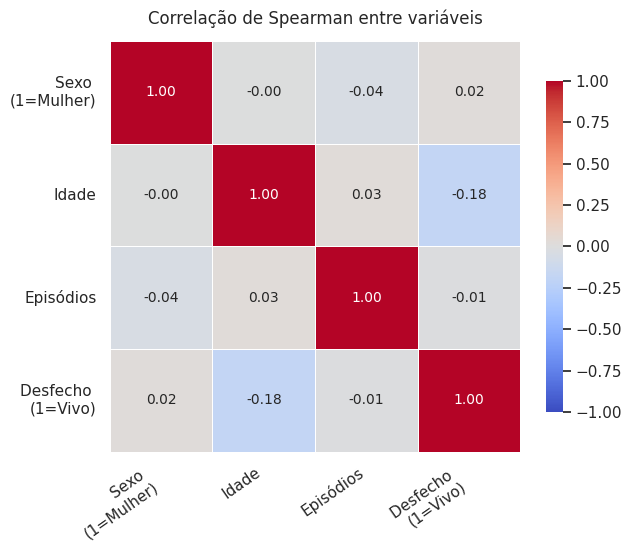

In [11]:
corr = df[[sexo, idade, eps, estado]].corr(method="spearman") #correlação de Pearson melhorada para outliers

labels = {sexo: "Sexo \n(1=Mulher)", idade: "Idade", eps: "Episódios", estado: "Desfecho \n(1=Vivo)"}
corr_renomeado = corr.rename(index=labels, columns=labels)

plt.figure(figsize=(6.5, 5.5)) #melhor para visualização
sns.heatmap(corr_renomeado, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 10}, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlação de Spearman entre variáveis", pad=12)
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


,pacientes,vivos,mortos,sobrevivencia,IC95% inf,IC95% sup
sexo,,,,,,
Feminino,52278,48713,3565,0.9318,0.9296,0.9340
Masculino,58063,53499,4564,0.9214,0.9192,0.9236


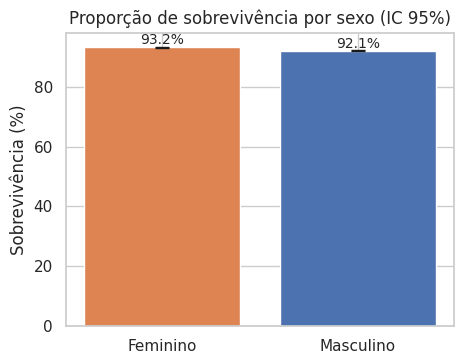

In [12]:
# proporção de sobrevivencia por sexo com intervalo de confiança 95%
g = df.groupby("sexo")[estado].agg(pacientes="size", vivos="sum")
g["mortos"] = g["pacientes"] - g["vivos"]
g["sobrevivencia"] = g["vivos"] / g["pacientes"]
g["ep"] = np.sqrt(g["sobrevivencia"] * (1 - g["sobrevivencia"]) / g["pacientes"])
g["IC95% inf"] = g["sobrevivencia"] - 1.96 * g["ep"]; g["IC95% sup"] = g["sobrevivencia"] + 1.96 * g["ep"]
display(g[["pacientes", "vivos", "mortos", "sobrevivencia", "IC95% inf", "IC95% sup"]].round(4))

plt.figure(figsize=(4.8, 3.8))
plt.bar(g.index, g["sobrevivencia"] * 100, yerr=1.96 * g["ep"] * 100, capsize=5, color=["#DD8452","#4C72B0", ])
for i, v in enumerate(g["sobrevivencia"] * 100):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10)
plt.ylabel("Sobrevivência (%)"); plt.title("Proporção de sobrevivência por sexo (IC 95%)"); plt.tight_layout(); plt.show()

In [13]:
tabela = pd.crosstab(df["sexo"], df["desfecho"])[["Vivo", "Morto"]]
display(tabela)
chi2, p_chi, gl, esperado = chi2_contingency(tabela, correction=False)
print(f"Qui-quadrado: chi2 = {chi2:.2f}, gl = {gl}, p = {p_chi:.4g} \nmenor frequência esperada = {esperado.min():.0f}   condição >= 5\n")

m = g.loc["Masculino"]; f = g.loc["Feminino"]
diff = f["sobrevivencia"] - m["sobrevivencia"]
ep_diff = np.sqrt(f["ep"] ** 2 + m["ep"] ** 2)
print(f"Diferença feminino - masculino: {diff * 100:+.2f}, IC 95% [{(diff - 1.96 * ep_diff) * 100:+.2f}; {(diff + 1.96 * ep_diff) * 100:+.2f}]")

phi = np.sqrt(chi2 / len(df)); print(f"phi (tamanho do efeito): {phi:.3f}")
# 0,1 pequeno  0,3 médio  0,5 grande

alpha = 0.05
print(f"\nDecisão:", "H0 rejeitada" if p_chi < alpha else "H0 não rejeitada")

desfecho,Vivo,Morto
sexo,,
Feminino,48713,3565
Masculino,53499,4564


Qui-quadrado: chi2 = 43.69, gl = 1, p = 3.841e-11 
menor frequência esperada = 3851   condição >= 5

Diferença feminino - masculino: +1.04, IC 95% [+0.73; +1.35]
phi (tamanho do efeito): 0.020

Decisão: H0 rejeitada


Registros com 1 episódio prévio: 84926


,pacientes,vivos,mortos,sobrevivencia,IC95% inf,IC95% sup
sexo,,,,,,
Feminino,41221,38474,2747,0.9334,0.9310,0.9358
Masculino,43705,40376,3329,0.9238,0.9213,0.9263


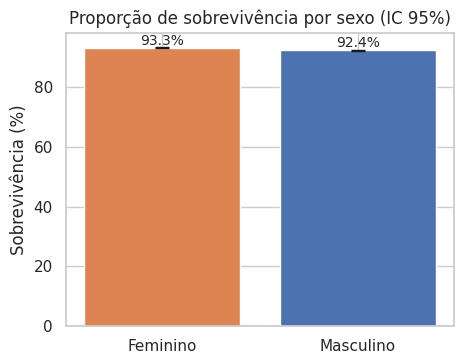

desfecho,Vivo,Morto
sexo,,
Feminino,38474,2747
Masculino,40376,3329


Qui-quadrado: chi2 = 29.00, gl = 1, p = 7.246e-08 
menor frequência esperada = 2949   condição >= 5

Diferença feminino - masculino: +0.95, IC 95% [+0.61; +1.30]
phi (tamanho do efeito): 0.018

Decisão: H0 rejeitada


In [20]:
df_p = df[df[eps] == 1].copy()
print("Registros com 1 episódio prévio:", len(df_p))
# repetiçao das análises para registros com 1 episódio

# proporção de sobrevivencia por sexo com intervalo de confiança 95%
g = df_p.groupby("sexo")[estado].agg(pacientes="size", vivos="sum")
g["mortos"] = g["pacientes"] - g["vivos"]
g["sobrevivencia"] = g["vivos"] / g["pacientes"]
g["ep"] = np.sqrt(g["sobrevivencia"] * (1 - g["sobrevivencia"]) / g["pacientes"])
g["IC95% inf"] = g["sobrevivencia"] - 1.96 * g["ep"]; g["IC95% sup"] = g["sobrevivencia"] + 1.96 * g["ep"]
display(g[["pacientes", "vivos", "mortos", "sobrevivencia", "IC95% inf", "IC95% sup"]].round(4))

plt.figure(figsize=(4.8, 3.8))
plt.bar(g.index, g["sobrevivencia"] * 100, yerr=1.96 * g["ep"] * 100, capsize=5, color=["#DD8452","#4C72B0", ])
for i, v in enumerate(g["sobrevivencia"] * 100):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10)
plt.ylabel("Sobrevivência (%)"); plt.title("Proporção de sobrevivência por sexo (IC 95%)"); plt.tight_layout(); plt.show()


tabela = pd.crosstab(df_p["sexo"], df_p["desfecho"])[["Vivo", "Morto"]]
display(tabela)
chi2, p_chi, gl, esperado = chi2_contingency(tabela, correction=False)
print(f"Qui-quadrado: chi2 = {chi2:.2f}, gl = {gl}, p = {p_chi:.4g} \nmenor frequência esperada = {esperado.min():.0f}   condição >= 5\n")

m = g.loc["Masculino"]; f = g.loc["Feminino"]
diff = f["sobrevivencia"] - m["sobrevivencia"]
ep_diff = np.sqrt(f["ep"] ** 2 + m["ep"] ** 2)
print(f"Diferença feminino - masculino: {diff * 100:+.2f}, IC 95% [{(diff - 1.96 * ep_diff) * 100:+.2f}; {(diff + 1.96 * ep_diff) * 100:+.2f}]")

phi = np.sqrt(chi2 / len(df_p)); print(f"phi (tamanho do efeito): {phi:.3f}")
# 0,1 pequeno  0,3 médio  0,5 grande

alpha = 0.05
print(f"\nDecisão:", "H0 rejeitada" if p_chi < alpha else "H0 não rejeitada")

In [16]:
m = smf.logit(f"{estado} ~ {sexo} + {idade} + {eps}", data=df).fit()
print(m.summary())

print()
coef = m.params[sexo]
ic = m.conf_int().loc[sexo]

val_or = np.exp(coef)
ic_or = np.exp(ic)

print(f"OR ajustada: {val_or:.3f}")
print(f"IC 95%: [{ic_or.iloc[0]:.3f}, {ic_or.iloc[1]:.3f}]")
print(f"p-valor: {m.pvalues[sexo]:.6g}")

Optimization terminated successfully.
         Current function value: 0.243546
         Iterations 8
                                 Logit Regression Results                                
Dep. Variable:     hospital_outcome_1alive_0dead   No. Observations:               110341
Model:                                     Logit   Df Residuals:                   110337
Method:                                      MLE   Df Model:                            3
Date:                           Tue, 24 Nov 2026   Pseudo R-squ.:                 0.07409
Time:                                   17:14:42   Log-Likelihood:                -26873.
converged:                                  True   LL-Null:                       -29023.
Covariance Type:                       nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Interc

pacientes           sobrevivencia          
sexo         Feminino Masculino      Feminino Masculino
faixa_idade                                            
<30              7140      6060         0.995     0.990
30-49            6720      6547         0.986     0.983
50-64            8679     11097         0.957     0.952
65-79           13576     18571         0.927     0.913
80+             16163     15788         0.872     0.858

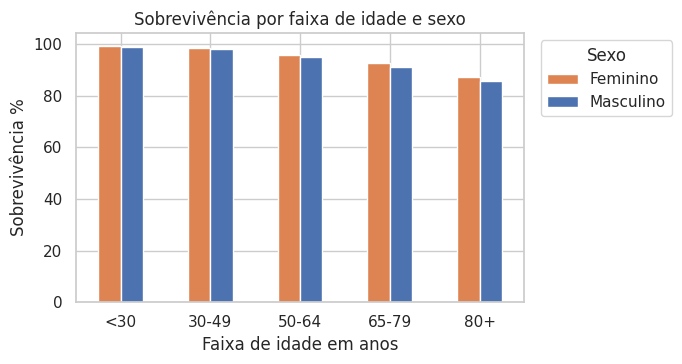

,Faixa,n_feminino,n_masculino,Sobrevivência feminina (%),Sobrevivência masculina (%),Diferença (p.p.),IC 95% inferior,IC 95% superior
0,<30,7140,6060,99.47,99.04,0.42,0.13,0.72
1,30-49,6720,6547,98.56,98.32,0.24,-0.19,0.66
2,50-64,8679,11097,95.75,95.20,0.55,-0.03,1.13
3,65-79,13576,18571,92.74,91.30,1.45,0.85,2.04
4,80+,16163,15788,87.16,85.77,1.39,0.64,2.14


In [19]:
faixas = [0, 30, 50, 65, 80, 200,]
rotulos = ['<30', '30-49', '50-64', '65-79', '80+']

df["faixa_idade"] = pd.cut(df[idade], bins=faixas, labels=rotulos, right=False)
estrato = df.groupby(["faixa_idade", "sexo"], observed=True)[estado].agg(pacientes="size", sobrevivencia="mean").unstack("sexo")
display(estrato.round(3))
(estrato["sobrevivencia"] * 100).plot(kind="bar", figsize=(7, 3.8), color=["#DD8452", "#4C72B0"])
plt.ylabel("Sobrevivência %");
plt.xlabel("Faixa de idade em anos");
plt.title("Sobrevivência por faixa de idade e sexo");
plt.xticks(rotation=0)
plt.legend(title="Sexo", bbox_to_anchor=(1.02, 1), loc="upper left",)
plt.tight_layout();
plt.show()

resultados_ic = []

for faixa in rotulos:
    sub = df[df["faixa_idade"] == faixa]

    f = sub[sub["sexo"] == "Feminino"][estado]
    m = sub[sub["sexo"] == "Masculino"][estado]

    n_f, n_m = len(f), len(m)
    p_f, p_m = f.mean(), m.mean()

    se_f = np.sqrt(p_f * (1 - p_f) / n_f)
    se_m = np.sqrt(p_m * (1 - p_m) / n_m)

    diff = p_f - p_m
    se_diff = np.sqrt(se_f**2 + se_m**2)

    resultados_ic.append({
        "Faixa": faixa,
        "n_feminino": n_f,
        "n_masculino": n_m,
        "Sobrevivência feminina (%)": p_f * 100,
        "Sobrevivência masculina (%)": p_m * 100,
        "Diferença (p.p.)": diff * 100,
        "IC 95% inferior": (diff - 1.96 * se_diff) * 100,
        "IC 95% superior": (diff + 1.96 * se_diff) * 100
    })

tabela_ic = pd.DataFrame(resultados_ic)

display(tabela_ic.round(2))